# How good are Sleeper's projections?

The trade desk values players from Sleeper's weekly projections, so it matters how well those
have held up. This joins every weekly projection stored in `player_weekly_projections`
(2020–2025) to what the player actually scored that week (Sleeper box scores), for every game
the player actually played.

Questions:
1. Are projections biased for any position?
2. Is the bias the same at every projection level (calibration)?
3. Does a player's history (last season, or his start this season) add anything the projection
   doesn't already know? Tested out of sample.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import query, style, load_weekly_actuals, POSITIONS, POS_COLORS, INK, INK_3, STAMP

style()
pd.set_option("display.precision", 2)

In [2]:
actual = load_weekly_actuals()
proj = query("""
    SELECT player_id, season, week, pts_ppr AS proj FROM player_weekly_projections
    WHERE pts_ppr IS NOT NULL
""", cache="weekly_projections")
games = actual.merge(proj, on=["player_id", "season", "week"])
games = games[games.proj > 0]
games["err"] = games.pts - games.proj
print(f"{len(games):,} player-games with a projection, {games.player_id.nunique():,} players")
games.groupby("position").agg(games=("err", "size"), mean_proj=("proj", "mean"),
                              mean_actual=("pts", "mean"), bias=("err", "mean"),
                              mae=("err", lambda e: e.abs().mean())).loc[POSITIONS]

33,688 player-games with a projection, 1,077 players


,games,mean_proj,mean_actual,bias,mae
position,,,,,
QB,3043,19.54,16.64,-2.90,6.47
RB,8844,7.50,7.61,0.11,4.16
WR,13960,7.46,7.24,-0.22,4.44
TE,7841,4.77,4.75,-0.02,3.23


## 1. Bias by position and season

Bias = actual minus projected points per game, for players with at least 6 games and a real
projection (4+ points a game). A negative value means the position was over-projected.

position,QB,RB,WR,TE
season,,,,
2020,-2.64,0.12,-0.31,-0.52
2021,-4.49,-0.10,-1.07,-0.82
2022,-3.65,0.03,-0.29,-0.26
2023,-2.32,0.67,0.15,0.69
2024,-1.79,0.75,0.34,0.69
2025,-2.66,-0.11,-0.49,0.25


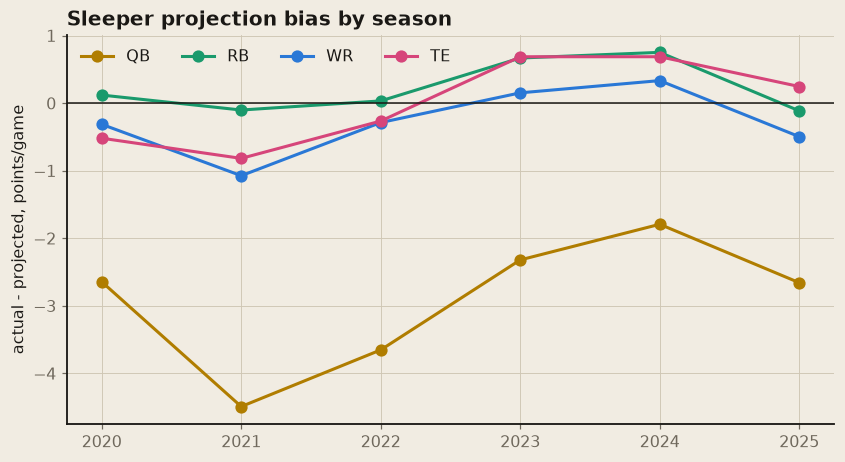

In [3]:
seasons = (games.groupby(["player_id", "season", "position"])
           .agg(proj=("proj", "mean"), actual=("pts", "mean"), gp=("pts", "size")).reset_index())
seasons = seasons[(seasons.gp >= 6) & (seasons.proj >= 4)]
seasons["bias"] = seasons.actual - seasons.proj
bias = seasons.pivot_table(index="season", columns="position", values="bias", aggfunc="mean")[POSITIONS]

fig, ax = plt.subplots()
for pos in POSITIONS:
    ax.plot(bias.index, bias[pos], marker="o", ms=7, color=POS_COLORS[pos], label=pos)
ax.axhline(0, color=INK, lw=1)
ax.set_ylabel("actual - projected, points/game")
ax.set_title("Sleeper projection bias by season")
ax.legend(ncol=4)
bias

## 2. Calibration: projected vs. actual by projection level

Each point is a bucket of player-seasons by projected points per game. A perfectly calibrated
projection sits on the dashed line.

position,QB,RB,TE,WR
bucket,,,,
"(4, 8]",NaN,5.7,5.7,5.3
"(8, 11]",NaN,9.7,9.5,9.2
"(11, 14]",NaN,13.2,12.1,12.1
"(14, 17]",13.0,15.8,NaN,15.4
"(17, 20]",15.6,18.2,NaN,18.2
"(20, 24]",18.5,NaN,NaN,NaN
"(24, 40]",22.5,NaN,NaN,NaN


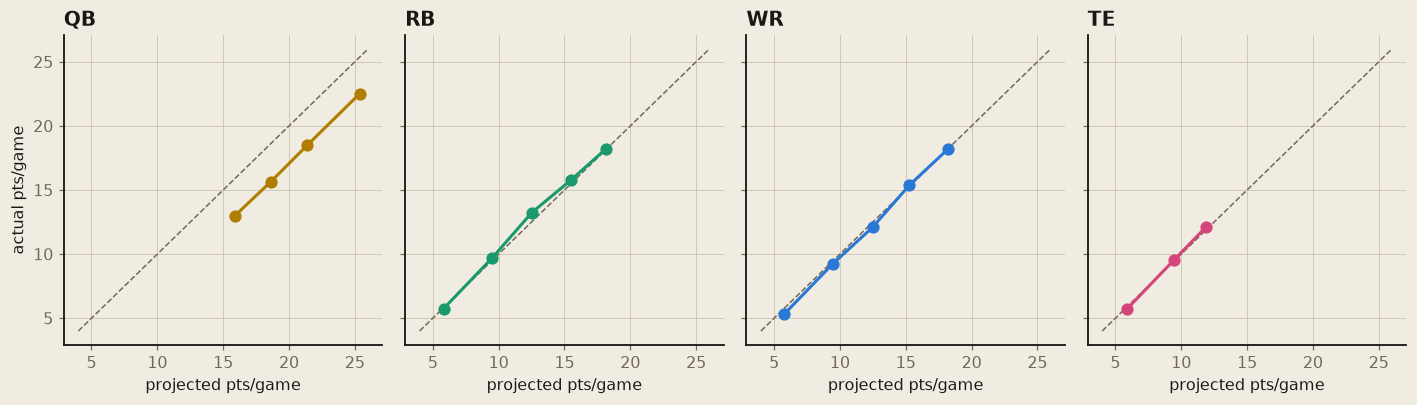

In [4]:
bins = [4, 8, 11, 14, 17, 20, 24, 40]
seasons["bucket"] = pd.cut(seasons.proj, bins)
cal = (seasons.groupby(["position", "bucket"], observed=True)
       .agg(proj=("proj", "mean"), actual=("actual", "mean"), n=("actual", "size"))
       .reset_index().query("n >= 15"))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), sharex=True, sharey=True)
for ax, pos in zip(axes, POSITIONS):
    c = cal[cal.position == pos]
    ax.plot([4, 26], [4, 26], ls="--", color=INK_3, lw=1)
    ax.plot(c.proj, c.actual, marker="o", ms=7, color=POS_COLORS[pos])
    ax.set_title(pos)
    ax.set_xlabel("projected pts/game")
axes[0].set_ylabel("actual pts/game")
fig.tight_layout()
cal.pivot(index="bucket", columns="position", values="actual").round(1)

### Is the QB gap just injuries?

A QB who gets hurt or benched mid-game scores far below a full-game projection. If that drove the
bias, it would vanish for QBs who started most of the season.

In [5]:
qb = seasons[seasons.position == "QB"]
pd.DataFrame({
    "player-seasons": [len(qb), (qb.gp >= 15).sum()],
    "mean projected": [qb.proj.mean(), qb[qb.gp >= 15].proj.mean()],
    "mean actual": [qb.actual.mean(), qb[qb.gp >= 15].actual.mean()],
    "bias": [qb.bias.mean(), qb[qb.gp >= 15].bias.mean()],
}, index=["all QBs (6+ games)", "15+ games"])

,player-seasons,mean projected,mean actual,bias
all QBs (6+ games),213,19.58,16.71,-2.87
15+ games,96,20.95,18.78,-2.16


## 3. Does history add anything? (out-of-sample backtest)

Models are fit on 2020–2023 and scored on 2024–2025, per position, predicting points per game
in weeks 7–17 from information available after week 6:

- **raw**: the average weekly projection for weeks 7–17
- **calibrated**: `a + b × projection` (fixes a constant bias)
- **+ last season**: also uses last season's actual points per game
- **+ hot start**: also uses how far the player beat or missed his projections in weeks 1–6

In [6]:
EARLY = 7
g = games.assign(early=games.week < EARLY)
agg = g.groupby(["player_id", "season", "position", "early"]).agg(
    proj=("proj", "mean"), pts=("pts", "mean"), n=("pts", "size")).unstack("early")
agg.columns = [f"{a}_{'early' if e else 'late'}" for a, e in agg.columns]
agg = agg.dropna().reset_index()
agg = agg[(agg.n_early >= 4) & (agg.n_late >= 5)]

last = seasons.set_index(["player_id", "season"]).actual
agg["last_season"] = [last.get((p, s - 1), np.nan) for p, s in zip(agg.player_id, agg.season)]
agg["hot_start"] = agg.pts_early - agg.proj_early

def fit_predict(train, test, cols):
    X = lambda d: np.column_stack([np.ones(len(d))] + [d[c].to_numpy() for c in cols])
    beta, *_ = np.linalg.lstsq(X(train), train.pts_late.to_numpy(), rcond=None)
    return X(test) @ beta

rows = []
for pos in POSITIONS:
    d = agg[(agg.position == pos)].dropna(subset=["last_season"])
    train, test = d[d.season < 2024], d[d.season >= 2024]
    y = test.pts_late.to_numpy()
    mae = lambda pred: np.abs(y - pred).mean()
    rows.append({
        "position": pos, "test player-seasons": len(test),
        "raw": mae(test.proj_late.to_numpy()),
        "calibrated": mae(fit_predict(train, test, ["proj_late"])),
        "+ last season": mae(fit_predict(train, test, ["proj_late", "last_season"])),
        "+ hot start": mae(fit_predict(train, test, ["proj_late", "hot_start"])),
    })
backtest = pd.DataFrame(rows).set_index("position")
backtest

,test player-seasons,raw,calibrated,+ last season,+ hot start
position,,,,,
QB,38,3.43,2.84,2.80,2.88
RB,84,1.84,1.84,1.87,1.85
WR,146,2.05,2.04,2.03,2.05
TE,54,1.77,1.84,1.87,1.84


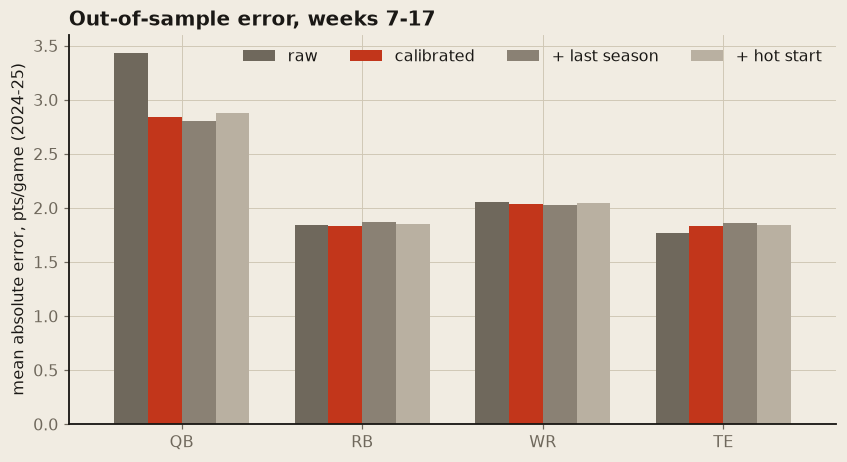

In [7]:
ax = backtest[["raw", "calibrated", "+ last season", "+ hot start"]].plot(
    kind="bar", width=0.75, color=[INK_3, STAMP, "#8a8174", "#b9b0a1"])
ax.set_ylabel("mean absolute error, pts/game (2024-25)")
ax.set_xlabel("")
ax.set_title("Out-of-sample error, weeks 7-17")
ax.tick_params(axis="x", rotation=0)
ax.legend(ncol=4, loc="upper right");

## Takeaways

Based on 33,688 player-games, 2020-2025.

- **RB, WR and TE projections are well calibrated.** Their bias stays within about ±1 point per
  game in every season, and the calibration curves sit on the diagonal at every level.
- **QBs are over-projected every season,** by 1.8 to 4.5 points per game (2.9 on average:
  19.5 projected vs. 16.6 actual). The gap is about the same at every projection level, so it
  isn't confined to backups.
- **It's not just injuries.** QBs who played 15+ games were still over-projected by 2.2 points
  per game.
- **History doesn't beat the projection, except to correct QBs.** Out of sample (2024-25), a
  simple `a + b × projection` correction cut QB error 17% (3.43 to 2.84). For RB/WR/TE nothing
  beat the raw projection. Neither last season's points nor a hot or cold start added
  anything, because Sleeper's weekly projections already absorb them.
- **What this means for the trade desk:** projections are the right base for player value,
  and the one change the data supports is a QB correction. Without it, QB points are projected
  about 15% too high, which matters most in superflex.